# **INFORMASI DATASET**

Dataset ini menyajikan gambaran mendalam mengenai perilaku transaksi dan pola aktivitas keuangan, sehingga sangat ideal untuk eksplorasi **deteksi penipuan (fraud detection)** dan **identifikasi anomali**. Dataset ini mencakup **2.512 sampel data transaksi**, yang mencakup berbagai atribut transaksi, demografi nasabah, dan pola penggunaan.

Setiap entri memberikan wawasan komprehensif terhadap perilaku transaksi, memungkinkan analisis untuk **keamanan finansial** dan pengembangan model prediktif.

## Fitur Utama

- **`TransactionID`**: Pengidentifikasi unik alfanumerik untuk setiap transaksi.  
- **`AccountID`**: ID unik untuk setiap akun, dapat memiliki banyak transaksi.  
- **`TransactionAmount`**: Nilai transaksi dalam mata uang, mulai dari pengeluaran kecil hingga pembelian besar.  
- **`TransactionDate`**: Tanggal dan waktu transaksi terjadi.  
- **`TransactionType`**: Tipe transaksi berupa `'Credit'` atau `'Debit'`.  
- **`Location`**: Lokasi geografis transaksi (nama kota di Amerika Serikat).  
- **`DeviceID`**: ID perangkat yang digunakan dalam transaksi.  
- **`IP Address`**: Alamat IPv4 yang digunakan saat transaksi, dapat berubah untuk beberapa akun.  
- **`MerchantID`**: ID unik merchant, menunjukkan merchant utama dan anomali transaksi.  
- **`AccountBalance`**: Saldo akun setelah transaksi berlangsung.  
- **`PreviousTransactionDate`**: Tanggal transaksi terakhir pada akun, berguna untuk menghitung frekuensi transaksi.  
- **`Channel`**: Kanal transaksi seperti `Online`, `ATM`, atau `Branch`.  
- **`CustomerAge`**: Usia pemilik akun.  
- **`CustomerOccupation`**: Profesi pengguna seperti `Dokter`, `Insinyur`, `Mahasiswa`, atau `Pensiunan`.  
- **`TransactionDuration`**: Lama waktu transaksi (dalam detik).  
- **`LoginAttempts`**: Jumlah upaya login sebelum transaksi—jumlah tinggi bisa mengindikasikan anomali.

Tugas kamu adalah membuat model clustering yang selanjutnya akan digunakan untuk membuat model klasifikasi.


# **Import Library**

In [711]:
#Type your code here
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder

# **Load Dataset**

In [712]:
# Load data
url='https://drive.google.com/uc?id=1gnLO9qvEPqv1uBt1928AcsCmdvzqjC5m'
df = pd.read_csv(url)

In [ ]:
df.head()

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70.0,Doctor,81.0,1.0,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68.0,Doctor,141.0,1.0,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19.0,Student,56.0,1.0,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26.0,Student,25.0,1.0,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,NaN,Student,198.0,1.0,7429.40,2024-11-04 08:06:39


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2537 entries, 0 to 2536
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2508 non-null   object 
 1   AccountID                2516 non-null   object 
 2   TransactionAmount        2511 non-null   float64
 3   TransactionDate          2509 non-null   object 
 4   TransactionType          2507 non-null   object 
 5   Location                 2507 non-null   object 
 6   DeviceID                 2507 non-null   object 
 7   IP Address               2517 non-null   object 
 8   MerchantID               2514 non-null   object 
 9   Channel                  2510 non-null   object 
 10  CustomerAge              2519 non-null   float64
 11  CustomerOccupation       2514 non-null   object 
 12  TransactionDuration      2511 non-null   float64
 13  LoginAttempts            2516 non-null   float64
 14  AccountBalance          

In [ ]:
df.describe()

,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
count,2511.000000,2519.000000,2511.000000,2516.000000,2510.000000
mean,297.656468,44.678444,119.422939,1.121622,5113.438124
std,292.230367,17.837359,70.078513,0.594469,3897.975861
min,0.260000,18.000000,10.000000,1.000000,101.250000
25%,81.310000,27.000000,63.000000,1.000000,1504.727500
50%,211.360000,45.000000,112.000000,1.000000,4734.110000
75%,413.105000,59.000000,161.000000,1.000000,7672.687500
max,1919.110000,80.000000,300.000000,5.000000,14977.990000


In [716]:
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numerical Columns:", numeric_cols)
print("Categorical Columns:", categorical_cols)


Numerical Columns: ['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']
Categorical Columns: ['TransactionID', 'AccountID', 'TransactionDate', 'TransactionType', 'Location', 'DeviceID', 'IP Address', 'MerchantID', 'Channel', 'CustomerOccupation', 'PreviousTransactionDate']


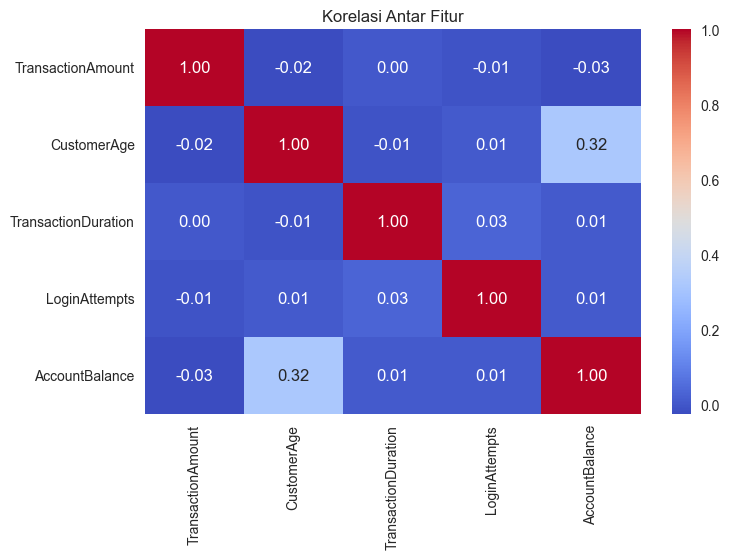

In [ ]:
# Menampilkan korelasi antar fitur
plt.figure(figsize=(8, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Korelasi Antar Fitur")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

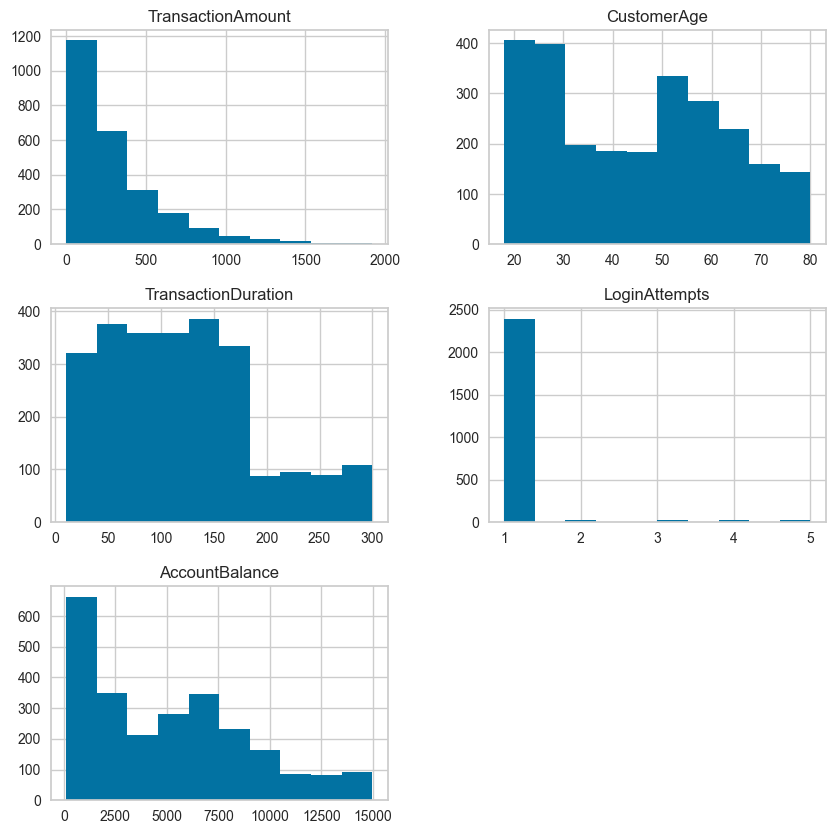

In [ ]:
# Menampilkan histogram untuk semua kolom numerik
df[numeric_cols].hist(figsize=(10, 10))
plt.show


C:\Users\Aflah Ghozi\AppData\Local\Temp\ipykernel_15384\2250974559.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


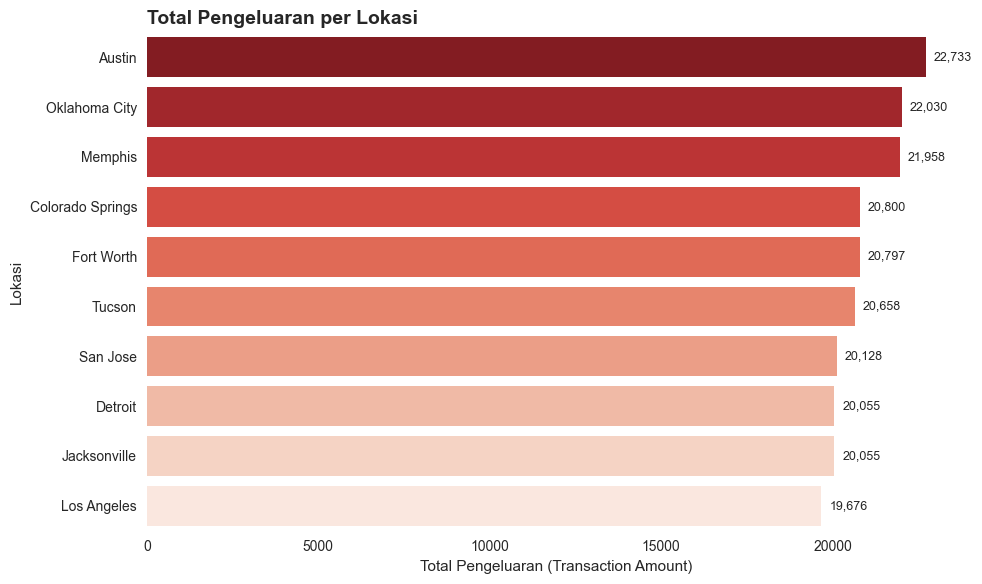

In [ ]:
# Hitung total pengeluaran per lokasi
total_spend = df.groupby('Location', as_index=False)['TransactionAmount'].sum()

total_spend = total_spend.sort_values('TransactionAmount', ascending=False)
total_spend = total_spend.head(10)

plt.figure(figsize=(10,6))
sns.barplot(
    data=total_spend,
    y='Location',
    x='TransactionAmount',
    palette='Reds_r'
)

for i, val in enumerate(total_spend['TransactionAmount']):
    plt.text(val + (0.01 * total_spend['TransactionAmount'].max()), i,
             f"{val:,.0f}", va='center', fontsize=9)

plt.title('Total Pengeluaran per Lokasi', fontsize=14, fontweight='bold', loc='left')
plt.xlabel('Total Pengeluaran (Transaction Amount)')
plt.ylabel('Lokasi')
plt.grid(False)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()


# **Preprocessing Data**

In [720]:
# Mengecek dataset menggunakan isnull().sum()
df.isnull().sum()

TransactionID              29
AccountID                  21
TransactionAmount          26
TransactionDate            28
TransactionType            30
Location                   30
DeviceID                   30
IP Address                 20
MerchantID                 23
Channel                    27
CustomerAge                18
CustomerOccupation         23
TransactionDuration        26
LoginAttempts              21
AccountBalance             27
PreviousTransactionDate    24
dtype: int64

In [721]:
# Mengecek dataset menggunakan duplicated().sum()
df.duplicated().sum()

np.int64(21)

In [ ]:
# Melakukan feature scaling menggunakan MinMaxScaler() atau StandardScalar() untuk fitur numerik.
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[numeric_cols] = scaler.fit_transform(df_scaled[numeric_cols])

df_scaled.head()

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,-0.970546,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,1.419862,Doctor,-0.548393,-0.204629,-0.000315,2024-11-04 08:08:08
1,TX000002,AC00455,0.268963,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,1.307715,Doctor,0.307960,-0.204629,2.218381,2024-11-04 08:09:35
2,TX000003,AC00019,-0.586526,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,-1.439874,Student,-0.905207,-0.204629,-1.024091,2024-11-04 08:07:04
3,TX000004,AC00070,-0.387294,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,-1.047361,Student,-1.347656,-0.204629,0.886694,2024-11-04 08:09:06
4,TX000005,AC00411,-0.972736,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,NaN,Student,1.121495,-0.204629,0.594263,2024-11-04 08:06:39


In [723]:
df_scaled.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2537 entries, 0 to 2536
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2508 non-null   object 
 1   AccountID                2516 non-null   object 
 2   TransactionAmount        2511 non-null   float64
 3   TransactionDate          2509 non-null   object 
 4   TransactionType          2507 non-null   object 
 5   Location                 2507 non-null   object 
 6   DeviceID                 2507 non-null   object 
 7   IP Address               2517 non-null   object 
 8   MerchantID               2514 non-null   object 
 9   Channel                  2510 non-null   object 
 10  CustomerAge              2519 non-null   float64
 11  CustomerOccupation       2514 non-null   object 
 12  TransactionDuration      2511 non-null   float64
 13  LoginAttempts            2516 non-null   float64
 14  AccountBalance          

In [724]:
# Melakukan drop pada kolom yang memiliki keterangan id dan IP Address
df_scaled = df_scaled.drop(columns=['TransactionID', 'AccountID', 'DeviceID', 'IP Address', 'MerchantID'])
df_scaled.head()

,TransactionAmount,TransactionDate,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,-0.970546,2023-04-11 16:29:14,Debit,San Diego,ATM,1.419862,Doctor,-0.548393,-0.204629,-0.000315,2024-11-04 08:08:08
1,0.268963,2023-06-27 16:44:19,Debit,Houston,ATM,1.307715,Doctor,0.307960,-0.204629,2.218381,2024-11-04 08:09:35
2,-0.586526,2023-07-10 18:16:08,Debit,Mesa,Online,-1.439874,Student,-0.905207,-0.204629,-1.024091,2024-11-04 08:07:04
3,-0.387294,2023-05-05 16:32:11,Debit,Raleigh,Online,-1.047361,Student,-1.347656,-0.204629,0.886694,2024-11-04 08:09:06
4,-0.972736,2023-10-16 17:51:24,Credit,Atlanta,Online,NaN,Student,1.121495,-0.204629,0.594263,2024-11-04 08:06:39


In [725]:
df_scaled['TransactionDate'] = pd.to_datetime(df_scaled['TransactionDate'])
df_scaled['PreviousTransactionDate'] = pd.to_datetime(df_scaled['PreviousTransactionDate'])

df_scaled['TransactionGap'] = (df_scaled['PreviousTransactionDate'] - df_scaled['TransactionDate']).dt.total_seconds()/ 3600
df_scaled = df_scaled.drop(columns=['TransactionDate','PreviousTransactionDate'])
df_scaled.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionGap
0,-0.970546,Debit,San Diego,ATM,1.419862,Doctor,-0.548393,-0.204629,-0.000315,13743.648333
1,0.268963,Debit,Houston,ATM,1.307715,Doctor,0.307960,-0.204629,2.218381,11895.421111
2,-0.586526,Debit,Mesa,Online,-1.439874,Student,-0.905207,-0.204629,-1.024091,11581.848889
3,-0.387294,Debit,Raleigh,Online,-1.047361,Student,-1.347656,-0.204629,0.886694,13167.615278
4,-0.972736,Credit,Atlanta,Online,NaN,Student,1.121495,-0.204629,0.594263,9230.254167


In [726]:
df_scaled.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2537 entries, 0 to 2536
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   TransactionAmount    2511 non-null   float64
 1   TransactionType      2507 non-null   object 
 2   Location             2507 non-null   object 
 3   Channel              2510 non-null   object 
 4   CustomerAge          2519 non-null   float64
 5   CustomerOccupation   2514 non-null   object 
 6   TransactionDuration  2511 non-null   float64
 7   LoginAttempts        2516 non-null   float64
 8   AccountBalance       2510 non-null   float64
 9   TransactionGap       2485 non-null   float64
dtypes: float64(6), object(4)
memory usage: 198.3+ KB


In [ ]:
# Melakukan feature encoding menggunakan LabelEncoder() untuk fitur kategorikal.
encoders = {}
categorical_cols = ['TransactionType', 'Location', 'Channel', 'CustomerOccupation']
for col in categorical_cols:
    le = LabelEncoder()
    df_scaled[col] = df_scaled[col].astype(str)
    df_scaled[col] = le.fit_transform(df_scaled[col])
    encoders[col] = le

df_scaled.head()


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionGap
0,-0.970546,1,36,0,1.419862,0,-0.548393,-0.204629,-0.000315,13743.648333
1,0.268963,1,15,0,1.307715,0,0.307960,-0.204629,2.218381,11895.421111
2,-0.586526,1,23,2,-1.439874,3,-0.905207,-0.204629,-1.024091,11581.848889
3,-0.387294,1,33,2,-1.047361,3,-1.347656,-0.204629,0.886694,13167.615278
4,-0.972736,0,1,2,NaN,3,1.121495,-0.204629,0.594263,9230.254167


In [728]:
df_scaled.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2537 entries, 0 to 2536
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   TransactionAmount    2511 non-null   float64
 1   TransactionType      2537 non-null   int64  
 2   Location             2537 non-null   int64  
 3   Channel              2537 non-null   int64  
 4   CustomerAge          2519 non-null   float64
 5   CustomerOccupation   2537 non-null   int64  
 6   TransactionDuration  2511 non-null   float64
 7   LoginAttempts        2516 non-null   float64
 8   AccountBalance       2510 non-null   float64
 9   TransactionGap       2485 non-null   float64
dtypes: float64(6), int64(4)
memory usage: 198.3 KB


In [ ]:
# checking seluruh fitur yang ada
df_scaled.columns.tolist()

['TransactionAmount',
 'TransactionType',
 'Location',
 'Channel',
 'CustomerAge',
 'CustomerOccupation',
 'TransactionDuration',
 'LoginAttempts',
 'AccountBalance',
 'TransactionGap']

In [730]:
df_scaled.isnull().sum()

TransactionAmount      26
TransactionType         0
Location                0
Channel                 0
CustomerAge            18
CustomerOccupation      0
TransactionDuration    26
LoginAttempts          21
AccountBalance         27
TransactionGap         52
dtype: int64

In [ ]:
# Menangani data yang hilang 
numerical_cols = ['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance', 'TransactionGap']
categorical_cols = ['TransactionType', 'Location', 'Channel', 'CustomerOccupation']

# Imputasi numerik dengan median
for col in numerical_cols:
    median_val = df_scaled[col].median()
    df_scaled[col] = df_scaled[col].fillna(median_val)

# Imputasi kategorikal dengan modus
for col in categorical_cols:
    mode_val = df_scaled[col].mode()[0]
    df_scaled[col] = df_scaled[col].fillna(mode_val)

print("Jumlah missing values setelah imputasi:\n", df_scaled.isnull().sum())
print("\nTipe data akhir:")
print(df.dtypes)

Jumlah missing values setelah imputasi:
 TransactionAmount      0
TransactionType        0
Location               0
Channel                0
CustomerAge            0
CustomerOccupation     0
TransactionDuration    0
LoginAttempts          0
AccountBalance         0
TransactionGap         0
dtype: int64

Tipe data akhir:
TransactionID               object
AccountID                   object
TransactionAmount          float64
TransactionDate             object
TransactionType             object
Location                    object
DeviceID                    object
IP Address                  object
MerchantID                  object
Channel                     object
CustomerAge                float64
CustomerOccupation          object
TransactionDuration        float64
LoginAttempts              float64
AccountBalance             float64
PreviousTransactionDate     object
dtype: object


In [ ]:
# Menghapus data duplikat
df_scaled = df_scaled.drop_duplicates().reset_index(drop=True)
df_scaled.duplicated().sum()

np.int64(0)

In [ ]:
# Melakukan Handling Outlier Data
# Metode IQR untuk deteksi outlier varibel numerik
def count_outliers_iqr(data, col_out):
    hasil = []
    for col in col_out:
        q1 = np.percentile(data[col], 25)
        q3 = np.percentile(data[col], 75)
        IQR = q3 - q1
        lwr_bound = q1 - (1.5 * IQR)
        upr_bound = q3 + (1.5 * IQR)

        # Cari outliers
        outliers = data[(data[col] < lwr_bound) | (data[col] > upr_bound)]
        jumlah_outlier = len(outliers)

        hasil.append({
            "Kolom": col,
            "Jumlah Outlier": jumlah_outlier
        })

    return pd.DataFrame(hasil)

jumlah_outlier_df = count_outliers_iqr(df_scaled, numerical_cols)

print(jumlah_outlier_df)

                 Kolom  Jumlah Outlier
0    TransactionAmount             113
1          CustomerAge               0
2  TransactionDuration               0
3        LoginAttempts             120
4       AccountBalance               0
5       TransactionGap               0


In [ ]:
def count_outliers_iqr(data, col_out):
    hasil = []
    for col in col_out:
        q1 = np.percentile(data[col], 25)
        q3 = np.percentile(data[col], 75)
        IQR = q3 - q1
        lower_bound = q1 - (1.5 * IQR)
        upper_bound = q3 + (1.5 * IQR)

        # Cari outliers
        outliers = data[(data[col] < lower_bound) | (data[col] > upper_bound)]
        jumlah_outlier = len(outliers)

        hasil.append({
            "Kolom": col,
            "Jumlah Outlier": jumlah_outlier,
            "Batas Bawah": lower_bound,
            "Batas Atas": upper_bound
        })

        # Print batas atas dan bawah
        f"{col} -> Batas Bawah: {lower_bound:.2f}, Batas Atas: {upper_bound:.2f}"

    return pd.DataFrame(hasil)


jumlah_outlier_df = count_outliers_iqr(df_scaled, numerical_cols)
print(jumlah_outlier_df)

                 Kolom  Jumlah Outlier  Batas Bawah    Batas Atas
0    TransactionAmount             113    -2.409928      2.059012
1          CustomerAge               0    -3.682803      3.494572
2  TransactionDuration               0    -2.903364      2.691476
3        LoginAttempts             120    -0.204629     -0.204629
4       AccountBalance               0    -3.278711      3.005261
5       TransactionGap               0  2897.167292  20558.406736


In [735]:
def handle_outliers(data, numerical_cols):
    for column in numerical_cols:
        Q1 = np.percentile(data[column], 25)
        Q3 = np.percentile(data[column], 75)
        IQR = Q3 - Q1 

        lower_bound = Q1 - (1.5 * IQR)
        upper_bound = Q3 + (1.5 * IQR)

        data[column] = np.where(data[column] < lower_bound, lower_bound, data[column])
        data[column] = np.where(data[column] > upper_bound, upper_bound, data[column])

handle_outliers(df_scaled, numerical_cols)

In [736]:
tot_outlier_df = count_outliers_iqr(df_scaled, numerical_cols)

print(tot_outlier_df)

                 Kolom  Jumlah Outlier  Batas Bawah    Batas Atas
0    TransactionAmount               0    -2.409928      2.059012
1          CustomerAge               0    -3.682803      3.494572
2  TransactionDuration               0    -2.903364      2.691476
3        LoginAttempts               0    -0.204629     -0.204629
4       AccountBalance               0    -3.278711      3.005261
5       TransactionGap               0  2897.167292  20558.406736


In [737]:
# Deteksi Outlier untuk data kategorik
df_scaled['TransactionType'].unique()
type_percentage = df_scaled['TransactionType'].value_counts(normalize=True) * 100
print(type_percentage)

rare_types = type_percentage[type_percentage < 1]
if not rare_types.empty:
    print(rare_types)
else:
    print("Tidak ada kategori dengan proporsi di bawah 1%.")

TransactionType
1    76.412092
0    22.394590
2     1.193317
Name: proportion, dtype: float64
Tidak ada kategori dengan proporsi di bawah 1%.


In [738]:
df_scaled['Location'].unique()
type_percentage = df_scaled['Location'].value_counts(normalize=True) * 100
print(type_percentage)

rare_types = type_percentage[type_percentage < 1]
if not rare_types.empty:
    print(rare_types)
else:
    print("Tidak ada kategori dengan proporsi di bawah 1%.")

Location
13    2.784407
20    2.744630
28    2.704853
40    2.704853
5     2.665076
30    2.665076
24    2.545744
29    2.505967
22    2.505967
15    2.505967
10    2.466189
11    2.466189
4     2.426412
6     2.386635
1     2.386635
39    2.386635
23    2.386635
33    2.346858
14    2.346858
7     2.346858
38    2.346858
17    2.346858
35    2.307080
16    2.307080
27    2.307080
18    2.307080
2     2.307080
36    2.267303
37    2.187749
19    2.187749
41    2.187749
31    2.187749
8     2.147971
26    2.147971
25    2.147971
34    2.068417
3     1.988862
21    1.988862
9     1.909308
12    1.829753
42    1.789976
32    1.670644
0     1.591090
43    1.193317
Name: proportion, dtype: float64
Tidak ada kategori dengan proporsi di bawah 1%.


In [739]:
df_scaled['Channel'].unique()
type_percentage = df_scaled['Channel'].value_counts(normalize=True) * 100
print(type_percentage)

rare_types = type_percentage[type_percentage < 1]
if not rare_types.empty:
    print(rare_types)
else:
    print("Tidak ada kategori dengan proporsi di bawah 1%.")

Channel
1    34.208433
0    32.895784
2    31.821798
3     1.073986
Name: proportion, dtype: float64
Tidak ada kategori dengan proporsi di bawah 1%.


In [740]:
df_scaled['CustomerOccupation'].unique()
type_percentage = df_scaled['CustomerOccupation'].value_counts(normalize=True) * 100
print(type_percentage)

rare_types = type_percentage[type_percentage < 1]
if not rare_types.empty:
    print(rare_types)
else:
    print("Tidak ada kategori dengan proporsi di bawah 1%.")

CustomerOccupation
3    25.934765
0    25.019889
1    24.701671
2    23.428799
4     0.914877
Name: proportion, dtype: float64
CustomerOccupation
4    0.914877
Name: proportion, dtype: float64


In [741]:
df_scaled['CustomerOccupation'] = df_scaled['CustomerOccupation'].replace(4, np.nan)
print(df_scaled['CustomerOccupation'].value_counts(dropna=False))

CustomerOccupation
3.0    652
0.0    629
1.0    621
2.0    589
NaN     23
Name: count, dtype: int64


In [742]:
mode_value = df_scaled['CustomerOccupation'].mode()[0]
df_scaled['CustomerOccupation'] = df_scaled['CustomerOccupation'].fillna(mode_value)

In [743]:
df_scaled['CustomerOccupation'].unique()
type_percentage = df_scaled['CustomerOccupation'].value_counts(normalize=True) * 100
print(type_percentage)

rare_types = type_percentage[type_percentage < 1]
if not rare_types.empty:
    print(rare_types)
else:
    print("Tidak ada kategori dengan proporsi di bawah 1%.")

CustomerOccupation
3.0    26.849642
0.0    25.019889
1.0    24.701671
2.0    23.428799
Name: proportion, dtype: float64
Tidak ada kategori dengan proporsi di bawah 1%.


In [ ]:
# Melakukan binning data berdasarkan kondisi rentang nilai pada fitur numerik,
# Kategorisasi AccountBalance ke 3 kelompok
df_scaled['AccountBalance'] = pd.qcut(
    df_scaled['AccountBalance'],
    q=3, 
    labels=['low', 'mid', 'high']
)

# Label encoding untuk AccountBalance
label_encoder_account = LabelEncoder()
df_scaled['AccountBalance'] = label_encoder_account.fit_transform(df_scaled['AccountBalance'])

df_scaled.head()


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionGap
0,-0.970546,1,36,0,1.419862,0.0,-0.548393,-0.204629,2,13743.648333
1,0.268963,1,15,0,1.307715,0.0,0.307960,-0.204629,0,11895.421111
2,-0.586526,1,23,2,-1.439874,3.0,-0.905207,-0.204629,1,11581.848889
3,-0.387294,1,33,2,-1.047361,3.0,-1.347656,-0.204629,0,13167.615278
4,-0.972736,0,1,2,0.018031,3.0,1.121495,-0.204629,0,9230.254167


# **Clustering Model**

In [ ]:
df_scaled.describe()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionGap
count,2514.000000,2514.000000,2514.000000,2514.00000,2514.000000,2514.000000,2514.000000,2.514000e+03,2514.000000,2514.000000
mean,-0.048151,0.787987,21.284010,1.01074,-0.003069,1.521082,0.000702,-2.046294e-01,1.000000,11706.030411
std,0.854233,0.437042,12.397534,0.83084,0.994836,1.134662,0.994014,5.552219e-17,0.816659,2531.486885
min,-1.017881,0.000000,0.000000,0.00000,-1.495947,0.000000,-1.561745,-2.046294e-01,0.000000,7381.747500
25%,-0.734076,1.000000,11.000000,0.00000,-0.991288,0.250000,-0.805299,-2.046294e-01,0.000000,9520.132083
50%,-0.295362,1.000000,21.000000,1.00000,0.018031,2.000000,-0.105944,-2.046294e-01,1.000000,11655.543611
75%,0.383159,1.000000,32.000000,2.00000,0.803056,3.000000,0.593411,-2.046294e-01,2.000000,13935.441944
max,2.059012,2.000000,43.000000,3.00000,1.980594,3.000000,2.577295,-2.046294e-01,2.000000,16120.185556


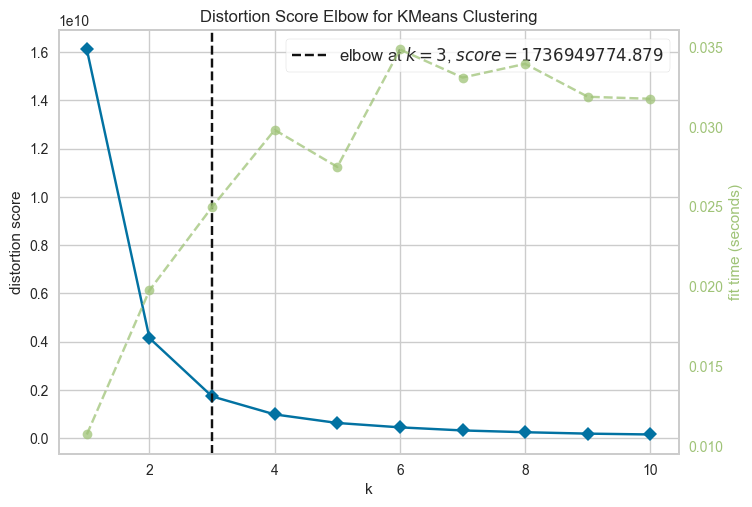

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
# Melakukan visualisasi Elbow Method menggunakan KElbowVisualizer()
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer
X = df_scaled.values

model = KMeans(random_state=42, n_init=10)

visualizer = KElbowVisualizer(model, k=(1, 11))
visualizer.fit(X)
visualizer.show()

In [747]:
# Menggunakan algoritma K-Means Clustering
cluster_model = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_model.fit(df_scaled)

,n_clusters,3
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [ ]:
# Menyimpan model clustering k-means
joblib.dump(cluster_model, "model_clustering.h5")

['model_clustering.h5']

In [749]:
# Menghitung dan menampilkan nilai Silhouette Score.
score = silhouette_score(df_scaled, cluster_model.labels_)
print(f'Silhouette Score: {score:.4f}')

Silhouette Score: 0.6007


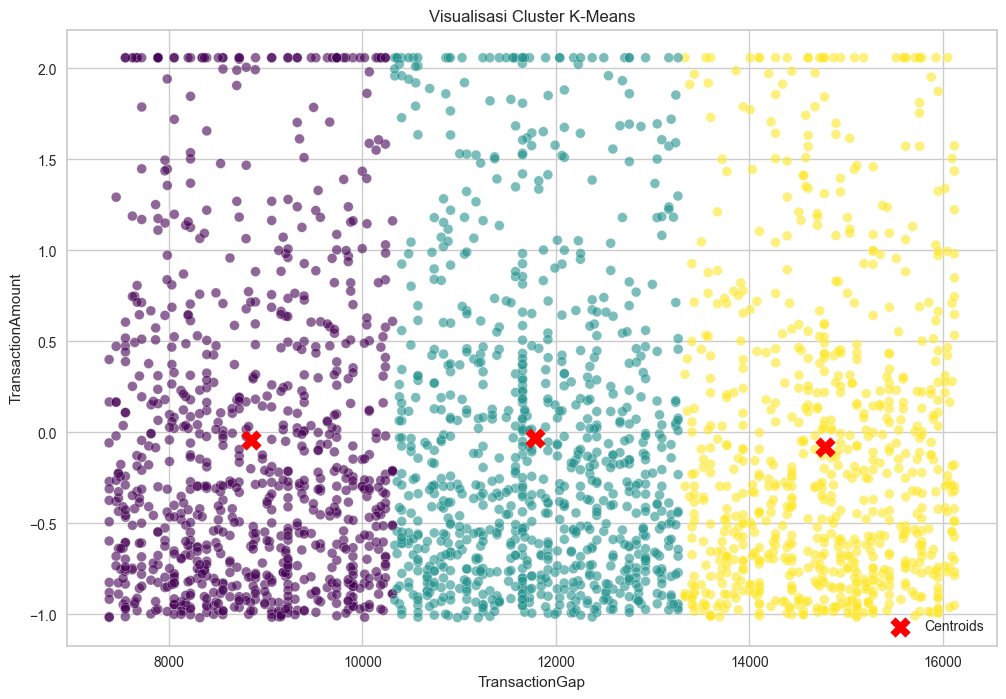

In [750]:
# Membuat visualisasi hasil clustering
# fitur untuk visualisasikan
features = ['TransactionGap', 'TransactionAmount']
X_vis = df_scaled[features].values

# Kmeans clustering
kmeans_vis = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_vis = kmeans_vis.fit_predict(X_vis)

# Centroid
centroids = kmeans_vis.cluster_centers_

# Visualisasi
plt.figure(figsize=(12,8))
plt.scatter(X_vis[:, 0], X_vis[:, 1], c=labels_vis, cmap='viridis', 
            s=50, alpha=0.6, edgecolors='w', marker='o')

plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, 
            marker='X', label='Centroids')

plt.title('Visualisasi Cluster K-Means')
plt.xlabel(features[0])
plt.ylabel(features[1])
plt.legend()
plt.show()

In [751]:
# Membangun model menggunakan PCA.
pca = PCA(n_components=2)
df_pca = pca.fit_transform(df_scaled)
# Menyimpan data PCA sebagai Dataframe dengan nama PCA_<numbers>
data_final = pd.DataFrame(df_pca, columns=['PCA1', 'PCA2'])
# Pastikan kamu membangun model Kmeans baru dengan data yang sudah dimodifikasi melalui PCA.
kmeans_pca = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_pca.fit(data_final)

,n_clusters,3
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


c:\Users\Aflah Ghozi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


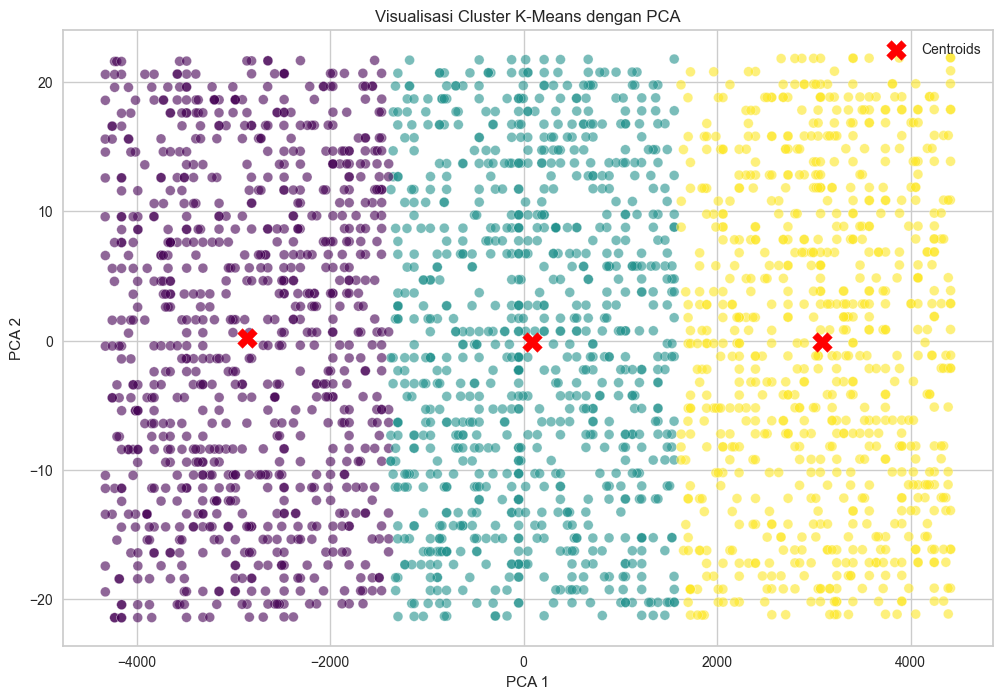

In [752]:
# centroid 
centroids_pca = pca.transform(cluster_model.cluster_centers_)

# Visualisasi
plt.figure(figsize=(12,8))
plt.scatter(data_final['PCA1'], data_final['PCA2'], c=labels_vis, cmap='viridis', 
            s=50, alpha=0.6, edgecolors='w', marker='o')

plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], c='red', s=200, 
            marker='X', label='Centroids')

plt.title('Visualisasi Cluster K-Means dengan PCA')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.show()

In [ ]:
# Menyimpan model PCA sebagai perbandingan
joblib.dump(kmeans_pca, "PCA_model_clustering.h5")

['PCA_model_clustering.h5']

# **Key Insight**

In [754]:
df_scaled.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2514 entries, 0 to 2513
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   TransactionAmount    2514 non-null   float64
 1   TransactionType      2514 non-null   int64  
 2   Location             2514 non-null   int64  
 3   Channel              2514 non-null   int64  
 4   CustomerAge          2514 non-null   float64
 5   CustomerOccupation   2514 non-null   float64
 6   TransactionDuration  2514 non-null   float64
 7   LoginAttempts        2514 non-null   float64
 8   AccountBalance       2514 non-null   int64  
 9   TransactionGap       2514 non-null   float64
dtypes: float64(6), int64(4)
memory usage: 196.5 KB


In [755]:
df_scaled

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionGap
0,-0.970546,1,36,0,1.419862,0.0,-0.548393,-0.204629,2,13743.648333
1,0.268963,1,15,0,1.307715,0.0,0.307960,-0.204629,0,11895.421111
2,-0.586526,1,23,2,-1.439874,3.0,-0.905207,-0.204629,1,11581.848889
3,-0.387294,1,33,2,-1.047361,3.0,-1.347656,-0.204629,0,13167.615278
4,-0.972736,0,1,2,0.018031,3.0,1.121495,-0.204629,0,9230.254167
...,...,...,...,...,...,...,...,...,...,...
2509,-0.920781,1,36,1,0.634836,2.0,0.379322,-0.204629,2,10574.996944
2510,-0.382263,1,10,2,-1.215581,3.0,-1.433292,-0.204629,1,14847.793333
2511,-0.186796,0,17,2,-1.159507,3.0,-0.377123,-0.204629,1,15087.773889
2512,-0.224308,1,29,0,-0.430555,1.0,-0.976570,-0.204629,2,7478.637222


In [756]:
cols_to_exclude_analysis = ['TransactionType', 'Location', 'Channel', 'CustomerAge', 'CustomerOccupation']
df_scaled['Cluster'] = kmeans_pca.labels_

numerical_cols = df_scaled.select_dtypes(include=np.number).columns.tolist()
analysis_cols = [col for col in numerical_cols if col not in cols_to_exclude_analysis and col != 'Cluster']
cluster_stats = df_scaled.groupby('Cluster')[analysis_cols].agg(['mean', 'min', 'max']).T

print("Hasil Analisis Cluster (tanpa drop kolom):")
print(cluster_stats)

Hasil Analisis Cluster (tanpa drop kolom):
Cluster                              0             1             2
TransactionAmount   mean     -0.040409     -0.028475     -0.079122
                    min      -1.017881     -1.017676     -1.015827
                    max       2.059012      2.059012      2.059012
TransactionDuration mean      0.033711      0.011464     -0.048209
                    min      -1.561745     -1.561745     -1.561745
                    max       2.577295      2.563023      2.563023
LoginAttempts       mean     -0.204629     -0.204629     -0.204629
                    min      -0.204629     -0.204629     -0.204629
                    max      -0.204629     -0.204629     -0.204629
AccountBalance      mean      0.963953      1.032955      1.002584
                    min       0.000000      0.000000      0.000000
                    max       2.000000      2.000000      2.000000
TransactionGap      mean   8849.516269  11788.239228  14786.467623
                   

## Karakteristik tiap cluster berdasarkan rentangnya.
1. **Cluster 0: (Low Risk)**:
   - **Rata-rata (mean) TransactionAmount:** -0.0404 <Sebelum inverse> <Setelah inverse>
   - **Rata-rata (mean) TransactionDuration:** 0.0337 <Sebelum inverse> <Setelah inverse>
   - **Rata-rata (mean) LoginAttempts:** -0.2046 <Sebelum inverse> <Setelah inverse>
   - **Rata-rata (mean) AccountBalance:** 0.9640 <Sebelum inverse> <Setelah inverse>
   - **Rata-rata (mean) TransactionGap (detik):** 8849.52 (~0.10 hari) <Sebelum inverse> <Setelah inverse>
   - **Analisis:** Cluster ini mencakup transaksi rutin dengan nominal kecil dan saldo akun rendah. TransactionGap pendek menunjukkan frekuensi transaksi cukup tinggi. Risiko fraud rendah, tapi tetap dipantau untuk transaksi abnormal.

---

2. **Cluster 1: (Medium Risk)**:
   - **Rata-rata (mean) TransactionAmount:** -0.0285 <Sebelum inverse> <Setelah inverse>
   - **Rata-rata (mean) TransactionDuration:** 0.0115 <Sebelum inverse> <Setelah inverse>
   - **Rata-rata (mean) LoginAttempts:** -0.2046 <Sebelum inverse> <Setelah inverse>
   - **Rata-rata (mean) AccountBalance:** 1.0330 <Sebelum inverse> <Setelah inverse>
   - **Rata-rata (mean) TransactionGap (detik):** 11788.24 (~0.14 hari) <Sebelum inverse> <Setelah inverse>
   - **Analisis:** Cluster ini melakukan transaksi dengan nominal sedang dan saldo akun relatif tinggi. TransactionGap lebih panjang → frekuensi transaksi lebih jarang. Cluster ini berpotensi menampilkan perilaku mencurigakan, sehingga perlu monitoring lebih ketat.

---

3. **Cluster 2: (High Risk)**:
   - **Rata-rata (mean) TransactionAmount:** -0.0791 <Sebelum inverse> <Setelah inverse>
   - **Rata-rata (mean) TransactionDuration:** -0.0482 <Sebelum inverse> <Setelah inverse>
   - **Rata-rata (mean) LoginAttempts:** -0.2046 <Sebelum inverse> <Setelah inverse>
   - **Rata-rata (mean) AccountBalance:** 1.0026 <Sebelum inverse> <Setelah inverse>
   - **Rata-rata (mean) TransactionGap (detik):** 14786.47 (~0.17 hari) <Sebelum inverse> <Setelah inverse>
   - **Analisis:** Cluster ini terdiri dari transaksi nominal tinggi dengan frekuensi jarang (TransactionGap terpanjang). Cluster ini berisiko tinggi terhadap fraud dan memerlukan perhatian ekstra untuk mendeteksi transaksi abnormal atau outlier.


# **Export Data**

In [ ]:
df_scaled = df_scaled.rename(columns={'Cluster': 'Target'})

In [758]:
df_scaled.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionGap,Target
0,-0.970546,1,36,0,1.419862,0.0,-0.548393,-0.204629,2,13743.648333,2
1,0.268963,1,15,0,1.307715,0.0,0.307960,-0.204629,0,11895.421111,1
2,-0.586526,1,23,2,-1.439874,3.0,-0.905207,-0.204629,1,11581.848889,1
3,-0.387294,1,33,2,-1.047361,3.0,-1.347656,-0.204629,0,13167.615278,1
4,-0.972736,0,1,2,0.018031,3.0,1.121495,-0.204629,0,9230.254167,0


In [759]:
# Simpan Data
df_scaled.to_csv('data_clustering.csv', index=False)

In [760]:
df_scaled

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionGap,Target
0,-0.970546,1,36,0,1.419862,0.0,-0.548393,-0.204629,2,13743.648333,2
1,0.268963,1,15,0,1.307715,0.0,0.307960,-0.204629,0,11895.421111,1
2,-0.586526,1,23,2,-1.439874,3.0,-0.905207,-0.204629,1,11581.848889,1
3,-0.387294,1,33,2,-1.047361,3.0,-1.347656,-0.204629,0,13167.615278,1
4,-0.972736,0,1,2,0.018031,3.0,1.121495,-0.204629,0,9230.254167,0
...,...,...,...,...,...,...,...,...,...,...,...
2509,-0.920781,1,36,1,0.634836,2.0,0.379322,-0.204629,2,10574.996944,1
2510,-0.382263,1,10,2,-1.215581,3.0,-1.433292,-0.204629,1,14847.793333,2
2511,-0.186796,0,17,2,-1.159507,3.0,-0.377123,-0.204629,1,15087.773889,2
2512,-0.224308,1,29,0,-0.430555,1.0,-0.976570,-0.204629,2,7478.637222,0


In [761]:
# inverse dataset ke rentang normal untuk numerikal
cols_to_inverse = [col for col in numeric_cols if col != 'AccountBalance']

inversed_data = scaler.inverse_transform(df_scaled[numeric_cols])
df_inversed = pd.DataFrame(inversed_data, index=df_scaled.index, columns=numeric_cols)
df_scaled[cols_to_inverse] = df_inversed[cols_to_inverse]

# tampilkan dataset yang sudah di-inverse
df_scaled.head()



,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionGap,Target
0,14.09,1,36,0,70.0,0.0,81.0,1.0,2,13743.648333,2
1,376.24,1,15,0,68.0,0.0,141.0,1.0,0,11895.421111,1
2,126.29,1,23,2,19.0,3.0,56.0,1.0,1,11581.848889,1
3,184.50,1,33,2,26.0,3.0,25.0,1.0,0,13167.615278,1
4,13.45,0,1,2,45.0,3.0,198.0,1.0,0,9230.254167,0


In [ ]:
df_scaled['AccountBalance'] = label_encoder_account.inverse_transform(df_scaled[['AccountBalance']])

df_scaled.head()

c:\Users\Aflah Ghozi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_label.py:151: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionGap,Target
0,14.09,1,36,0,70.0,0.0,81.0,1.0,mid,13743.648333,2
1,376.24,1,15,0,68.0,0.0,141.0,1.0,high,11895.421111,1
2,126.29,1,23,2,19.0,3.0,56.0,1.0,low,11581.848889,1
3,184.50,1,33,2,26.0,3.0,25.0,1.0,high,13167.615278,1
4,13.45,0,1,2,45.0,3.0,198.0,1.0,high,9230.254167,0


In [ ]:
# Inverse dataset yang sudah diencode ke kategori aslinya.
for col in categorical_cols:
    le = encoders[col]
    
    df_scaled[col] = le.inverse_transform(df_scaled[col].astype(int))

# Tampilkan dataset yang sudah di-inverse
df_scaled.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionGap,Target
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,mid,13743.648333,2
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,high,11895.421111,1
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,low,11581.848889,1
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,high,13167.615278,1
4,13.45,Credit,Atlanta,Online,45.0,Student,198.0,1.0,high,9230.254167,0


In [ ]:
numerical_cols = df_scaled.select_dtypes(include=np.number).columns.drop('Target').tolist()
categorical_cols = ['TransactionType', 'Location', 'Channel', 'CustomerOccupation', 'AccountBalance']

# Analisis deskriptif untuk variabel numerik per cluster
print("Analisis Deskriptif Fitur Numerik per Cluster (Setelah Inverse Transform):")
numerical_analysis = df_scaled.groupby('Target')[numerical_cols].agg(['mean', 'min', 'max']).T
display(numerical_analysis)


# Analisis deskriptif untuk fitur kategorik per cluster
print("\n" + "="*80 + "\n") # Pemisah agar lebih rapi
print("Analisis Deskriptif Fitur Kategorikal per Cluster (Setelah Inverse Transform):")
# Menggunakan lambda untuk mengambil modus pertama jika ada lebih dari satu
categorical_analysis = df_scaled.groupby('Target')[categorical_cols].agg(lambda x: x.mode()[0])
display(categorical_analysis)

Analisis Deskriptif Fitur Numerik per Cluster (Setelah Inverse Transform):


Target                               0             1             2
TransactionAmount   mean    285.850087    289.336804    274.539160
                    min       0.260000      0.320000      0.860000
                    max     899.242500    899.242500    899.242500
CustomerAge         mean     44.783721     45.334091     43.638243
                    min      18.000000     18.000000     18.000000
                    max      80.000000     80.000000     80.000000
TransactionDuration mean    121.784884    120.226136    116.045220
                    min      10.000000     10.000000     10.000000
                    max     300.000000    299.000000    299.000000
LoginAttempts       mean      1.000000      1.000000      1.000000
                    min       1.000000      1.000000      1.000000
                    max       1.000000      1.000000      1.000000
TransactionGap      mean   8849.516269  11788.239228  14786.467623
                    min    7381.747500  10334.423611  13333.328333
                    max   10312.040556  13263.963333  16120.185556



Analisis Deskriptif Fitur Kategorikal per Cluster (Setelah Inverse Transform):


,TransactionType,Location,Channel,CustomerOccupation,AccountBalance
Target,,,,,
0,Debit,Colorado Springs,Branch,Student,high
1,Debit,Los Angeles,Branch,Student,low
2,Debit,Miami,Branch,Student,low


## Menjelaskan karakteristik tiap cluster berdasarkan rentangnya setelah inverse.
1. **Cluster 0: (Transaksi Aman dan Stabil)**:  
- **Rata-rata (mean) TransactionAmount:** (Skala: -0.040) (Inverse: 285.85)  
- **Rata-rata (mean) AccountBalance:** (Skala: 0.964) (Inverse: High)  
- **Rata-rata (mean) TransactionDuration:** (Skala: 0.034) (Inverse: 121.78)  
- **Mode TransactionType:** Debit  
- **Mode Channel:** Branch  
- **Mode CustomerOccupation:** Student  
- **Analisis:** Berdasarkan data inverse, Cluster 0 memiliki rata-rata jumlah transaksi sekitar 286, saldo akun tergolong tinggi, dan durasi transaksi yang stabil di sekitar 122 detik. Mode fitur kategorikal menunjukkan transaksi debit yang dilakukan melalui cabang oleh pelanggan dengan pekerjaan mahasiswa. Karakteristik ini menggambarkan aktivitas transaksi yang normal dan minim indikasi fraud.

---

2. **Cluster 1: (Transaksi Frekuen dengan Saldo Rendah)**:  
- **Rata-rata (mean) TransactionAmount:** (Skala: -0.028) (Inverse: 289.33)  
- **Rata-rata (mean) AccountBalance:** (Skala: 1.033) (Inverse: Low)  
- **Rata-rata (mean) TransactionDuration:** (Skala: 0.011) (Inverse: 120.23)  
- **Mode TransactionType:** Debit  
- **Mode Channel:** Branch  
- **Mode CustomerOccupation:** Student  
- **Analisis:** Berdasarkan data inverse, Cluster 1 memiliki rata-rata nilai transaksi yang sedikit lebih tinggi, namun dilakukan oleh pelanggan dengan saldo akun rendah. Pola transaksi debit yang sering melalui cabang menunjukkan perilaku yang cenderung aktif, sehingga perlu pengawasan karena dapat mengindikasikan aktivitas tidak wajar seperti *small amount fraud* atau *frequent testing behavior*.

---

3. **Cluster 2: (Aktivitas Intens dan Potensi Fraud)**:  
- **Rata-rata (mean) TransactionAmount:** (Skala: -0.079) (Inverse: 274.53)  
- **Rata-rata (mean) AccountBalance:** (Skala: 1.003) (Inverse: Low)  
- **Rata-rata (mean) TransactionDuration:** (Skala: -0.048) (Inverse: 116.05)  
- **Mode TransactionType:** Debit  
- **Mode Channel:** Branch  
- **Mode CustomerOccupation:** Student  
- **Analisis:** Berdasarkan data inverse, Cluster 2 menunjukkan aktivitas transaksi dengan nilai relatif lebih kecil namun frekuensi tinggi dan jarak antar transaksi yang singkat. Pola ini umum pada aktivitas mencurigakan seperti *account takeover*, *smurfing*, atau penggunaan akun berulang dalam waktu singkat. Oleh karena itu, cluster ini tergolong berisiko tinggi dan perlu ditandai sebagai kandidat fraud.


In [765]:
# Mengintegrasikan kembali data yang telah di-inverse dengan hasil cluster.
df_scaled.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionGap,Target
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,mid,13743.648333,2
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,high,11895.421111,1
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,low,11581.848889,1
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,high,13167.615278,1
4,13.45,Credit,Atlanta,Online,45.0,Student,198.0,1.0,high,9230.254167,0


In [766]:
# Simpan Data
df_scaled.to_csv('data_clustering_inverse.csv', index=False)

End of Code.